# 02 · Sea surface maps (3-D)

This notebook runs xrMHW on a map of daily sea surface temperature (time, latitude,
longitude), the most common use. It covers unit conversion, chunking, maps of a
single day, how often each cell is in a marine heatwave, and marine cold spells.

The data are OSTIA SST from 1990 to 2022 off the Pacific coast of Baja California,
a region shaped by El Niño and La Niña and by the 2014–2016 north-east Pacific
warm anomaly.

In [1]:
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import xarray as xr
from matplotlib.colors import BoundaryNorm, ListedColormap

import xrMHW

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9,
})
INK, INK2 = "#0b0b0b", "#52514e"
WARM, COOL = "#e34948", "#2a78d6"          # marine heatwaves / marine cold spells
CAT_COLORS = ["#d3957f", "#c0583b", "#9d1926", "#5c0e21"]
CAT_NAMES = ["Moderate", "Strong", "Severe", "Extreme"]
LAND = "#e7e6e2"

EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("xrmhw"),
    base_url="doi:10.5281/zenodo.22909109/",
    registry={
        "xrmhw_glorys_4d_subset.nc": "md5:5555737e45f1c6cde9f657e50f456693",
        "xrmhw_ostia_sst_3d.nc": "md5:74a2da227394e4463f203f6b388518ee",
    },
)
ostia = xr.open_dataset(EXAMPLE_DATA.fetch("xrmhw_ostia_sst_3d.nc"))
ostia

<xarray.Dataset> Size: 89MB
Dimensions:       (time: 12054, latitude: 41, longitude: 45)
Coordinates:
  * time          (time) datetime64[ns] 96kB 1990-01-01 ... 2023-01-01
  * latitude      (latitude) float32 164B 26.33 26.38 26.42 ... 28.27 28.33
  * longitude     (longitude) float32 180B -116.0 -116.0 ... -113.9 -113.8
Data variables:
    analysed_sst  (time, latitude, longitude) float32 89MB ...
Attributes:
    source:                    AMSR2-REMSS-L2P-v2.0, AMSRE-REMSS-L2P-v2.0, GO...
    references:                Donlon, C.J., Martin, M., Stark, J.D., Roberts...
    comment:                   WARNING Some applications are unable to proper...
    title:                     Global SST & Sea Ice Analysis, L4 OSTIA, 0.05 ...
    history:                   Created from sst.nc; obs_anal.nc; seaice.nc; 2...
    Conventions:               CF-1.4, ACDD-1.3
    institution:               UKMO
    copernicusmarine_version:  2.2.4

## 1. Prepare the input

### Make sure the temperature is in °C

Detection itself does not depend on the unit, because an anomaly of 1 K is an
anomaly of 1 °C. But xrMHW labels its climatology and threshold in °C, so the input
should be in °C. Check the values, not only the `units` attribute: in this file the
attribute says kelvin, but the values are already in °C (notebook 00). The function
below decides from the values, converts real kelvin, and fixes the attribute.

In [2]:
def to_celsius(da):
    """Return da in °C, deciding from its values (the units attribute may be wrong)."""
    vmax = float(da.max())
    if vmax > 200:            # sea water in kelvin is about 271-310 K
        da = da - 273.15
        print("converted from kelvin")
    else:
        print(f"values up to {vmax:.1f}: already °C (attribute said "
              f"'{da.attrs.get('units')}')")
    return da.assign_attrs(units="degC")


sst = to_celsius(ostia["analysed_sst"])
ds = sst.to_dataset(name="sst")
ocean = ds["sst"].isel(time=0).notnull()
print(f"{int(ocean.sum())} cells with data of {ocean.size}; SST from "
      f"{float(ds.sst.min()):.1f} to {float(ds.sst.max()):.1f} °C")

values up to 30.2: already °C (attribute said 'kelvin')
232 cells with data of 1845; SST from 11.8 to 30.2 °C


### Chunk over space, keep time whole

xrMHW needs each cell's complete record in one piece to compute its climatology,
so `time` must be a single chunk (`-1`). Split the spatial dimensions instead, so
that Dask can process several blocks at once. For a small grid like this one the
choice barely matters; notebook 04 explains how to choose chunk sizes for large
datasets.

In [4]:
ds = ds.chunk({"time": -1, "latitude": 21, "longitude": 23})
ds["sst"].data

dask.array<xarray-sst, shape=(12054, 41, 45), dtype=float32, chunksize=(12054, 21, 23), chunktype=numpy.ndarray>

## 2. Run the detection

The baseline is the 1991–2020 WMO climate normal. The call builds a lazy Dask
graph; nothing is computed until `.compute()` (or a plot, or a write) asks for
values. Here we ask only for the fields used below.

In [5]:
CLIM = (1991, 2020)
mhw = xrMHW.xrMHW_func(ds, "sst", clim_period=CLIM,
                       output_vars=["intensity", "severity", "category"])
print("lazy result:", {v: mhw[v].data.chunksize for v in mhw.data_vars})
mhw = mhw.compute()

lazy result: {'mhw_intensity': (21, 23, 12054), 'mhw_severity': (21, 23, 12054), 'mhw_category': (21, 23, 12054)}


## 3. A map of one day

Pick the day with the highest mean severity during the 2014–2016 warm period and
map temperature, intensity and severity. Cells not in a marine heatwave that day
are left blank in the event fields.

day shown: 2015-05-03


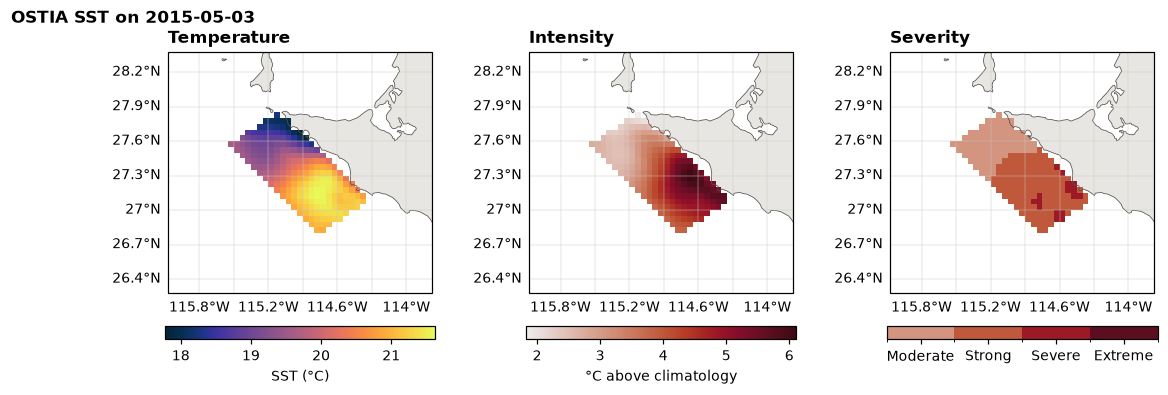

In [6]:
mean_sev = mhw["mhw_severity"].fillna(0).where(ocean).mean(("latitude", "longitude"))
day = mean_sev.sel(time=slice("2014", "2016")).idxmax("time").values
day_str = str(day)[:10]
print("day shown:", day_str)

extent = [float(ds.longitude.min()) - 0.05, float(ds.longitude.max()) + 0.05,
          float(ds.latitude.min()) - 0.05, float(ds.latitude.max()) + 0.05]


def base_map(ax, title):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor=LAND, zorder=0)
    ax.coastlines("10m", lw=0.5, color=INK2)
    gl = ax.gridlines(draw_labels=True, lw=0.3, color="#c9c8c3")
    gl.top_labels = gl.right_labels = False
    ax.set_title(title, loc="left")


fig, axes = plt.subplots(1, 3, figsize=(12, 3.8),
                         subplot_kw={"projection": ccrs.PlateCarree()})
fields = [
    (ds["sst"].sel(time=day), cmocean.cm.thermal, None, "SST (°C)", "Temperature"),
    (mhw["mhw_intensity"].sel(time=day), cmocean.cm.amp, None, "°C above climatology",
     "Intensity"),
]
for ax, (field, cmap, norm, label, title) in zip(axes[:2], fields):
    base_map(ax, title)
    m = ax.pcolormesh(ds.longitude, ds.latitude, field, cmap=cmap, norm=norm,
                      transform=ccrs.PlateCarree())
    fig.colorbar(m, ax=ax, orientation="horizontal", pad=0.1, shrink=0.9, label=label)

# Severity with a discrete colour for each category band (1-2, 2-3, 3-4, >4)
cat_cmap = ListedColormap(CAT_COLORS)
cat_norm = BoundaryNorm([1, 2, 3, 4, 5], cat_cmap.N)
base_map(axes[2], "Severity")
m = axes[2].pcolormesh(ds.longitude, ds.latitude, mhw["mhw_severity"].sel(time=day).clip(max=4.99),
                       cmap=cat_cmap, norm=cat_norm, transform=ccrs.PlateCarree())
cb = fig.colorbar(m, ax=axes[2], orientation="horizontal", pad=0.1, shrink=0.9,
                  ticks=[1.5, 2.5, 3.5, 4.5])
cb.ax.set_xticklabels(CAT_NAMES)
fig.suptitle(f"OSTIA SST on {day_str}", x=0.02, ha="left", fontweight="bold")
plt.show()

Intensity is the anomaly in °C; severity divides it by the local "distance" between
the threshold and the climatology, so it shows how unusual the warming is for each
place (Sen Gupta et al. 2020). Where temperature is usually more variable, the same anomaly gives a lower
severity. The two maps need not agree, and that is why both exist.

## 4. How much of the region is in a marine heatwave, and when

A time series of the fraction of cells in an event summarises a map through
time. The same calculation with `cold_spells=True` gives the fraction in a marine
cold spell, the cold counterpart defined with the 10th percentile. Plotting cold
spells downwards shows both on one axis.

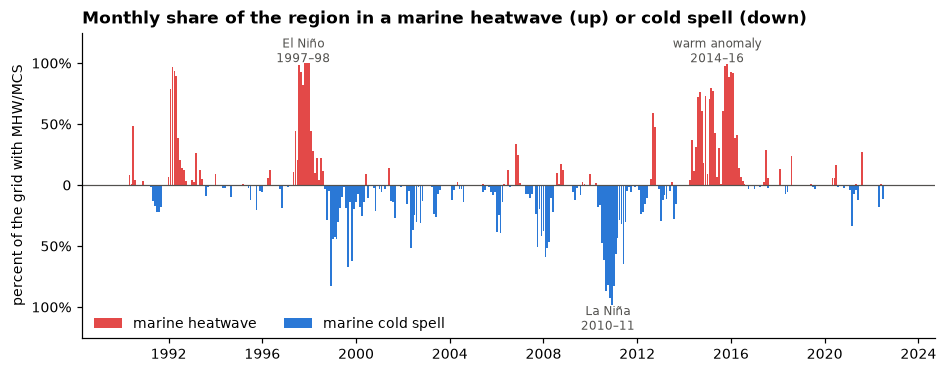

In [11]:
mcs = xrMHW.xrMHW_func(ds, "sst", clim_period=CLIM, cold_spells=True,
                       output_vars=["severity", "category"]).compute()
n_ocean = int(ocean.sum())
frac_mhw = (mhw["mhw_severity"].notnull().sum(("latitude", "longitude")) / n_ocean)
frac_mcs = (mcs["mcs_severity"].notnull().sum(("latitude", "longitude")) / n_ocean)
monthly = pd.DataFrame({"mhw": frac_mhw.to_series(), "mcs": frac_mcs.to_series()}
                       ).resample("MS").mean()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(monthly.index, monthly["mhw"], width=28, color=WARM, label="marine heatwave")
ax.bar(monthly.index, -monthly["mcs"], width=28, color=COOL, label="marine cold spell")
ax.axhline(0, color=INK2, lw=0.8)
ax.set_ylim(-1.25, 1.25)
ax.set_yticks([-1, -0.5, 0, 0.5, 1], ["100%", "50%", "0", "50%", "100%"])
ax.set_ylabel("percent of the grid with MHW/MCS")
ax.set_title("Monthly share of the region in a marine heatwave (up) or cold spell (down)",
             loc="left")
for x, text in [("1997-10-01", "El Niño\n1997–98"), ("2015-06-01", "warm anomaly\n2014–16"),
                ("2010-10-01", "La Niña\n2010–11")]:
    y = 1.22 if "Niña" not in text else -1.22
    ax.text(pd.Timestamp(x), y, text, ha="center", va="top" if y > 0 else "bottom",
            fontsize=8, color=INK2)
ax.legend(frameon=False, loc="lower left", ncol=2, bbox_to_anchor=(0, -0.02))
plt.show()

## 5. Where: event days in one year

Summing the event mask over a year gives, for each cell, the number of days spent
in an event. The maps compare the warmest year of the record for marine heatwaves
with the coldest for cold spells.

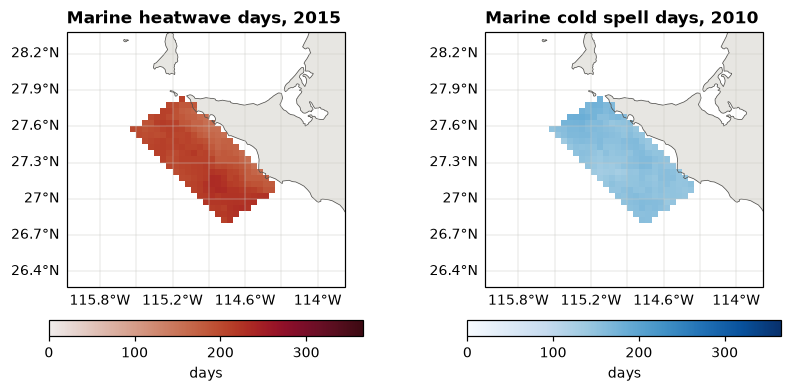

In [8]:
mhw_days = mhw["mhw_severity"].notnull().groupby("time.year").sum().where(ocean)
mcs_days = mcs["mcs_severity"].notnull().groupby("time.year").sum().where(ocean)
warm_year = int(mhw_days.mean(("latitude", "longitude")).idxmax())
cold_year = int(mcs_days.mean(("latitude", "longitude")).idxmax())

fig, axes = plt.subplots(1, 2, figsize=(9, 4),
                         subplot_kw={"projection": ccrs.PlateCarree()})
for ax, field, cmap, title in [
        (axes[0], mhw_days.sel(year=warm_year), cmocean.cm.amp,
         f"Marine heatwave days, {warm_year}"),
        (axes[1], mcs_days.sel(year=cold_year), plt.cm.Blues,
         f"Marine cold spell days, {cold_year}")]:
    base_map(ax, title)
    m = ax.pcolormesh(ds.longitude, ds.latitude, field, cmap=cmap, vmin=0, vmax=366,
                      transform=ccrs.PlateCarree())
    fig.colorbar(m, ax=ax, orientation="horizontal", pad=0.1, shrink=0.9, label="days")
plt.show()

## 6. Keep heatwaves and cold spells in one file

Output names carry a prefix, `mhw_` or `mcs_`, so the two results merge without
name clashes. Compress the event fields when writing: they are mostly empty.

In [9]:
both = xr.merge([mhw, mcs], compat="override")
encoding = {v: {"zlib": True, "complevel": 4} for v in both.data_vars}
out_dir = Path("xrmhw_outputs")
out_dir.mkdir(exist_ok=True)
both.to_netcdf(out_dir / "ostia_mhw_mcs.nc", encoding=encoding)
print(list(both.data_vars))
print(f"file size {(out_dir / 'ostia_mhw_mcs.nc').stat().st_size / 1e6:.1f} MB "
      f"(in memory {both.nbytes / 1e6:.0f} MB)")

['mhw_intensity', 'mhw_severity', 'mhw_category', 'mcs_severity', 'mcs_category']
file size 3.3 MB (in memory 445 MB)


## Summary

- Convert kelvin to °C and keep `time` in one chunk before calling xrMHW.
- Severity and category make maps comparable between places; intensity in °C does
  not.
- `cold_spells=True` detects marine cold spells with the same call; the `mcs_`
  prefix lets you merge both results.

Next: **03 · Subsurface marine heatwaves**.

### References

- Hobday, A. J., et al. (2016). *Progress in Oceanography*, 141, 227–238. https://doi.org/10.1016/j.pocean.2015.12.014
- Hobday, A. J., et al. (2018). *Oceanography*, 31(2), 162–173. https://doi.org/10.5670/oceanog.2018.205
- Schlegel, R. W., Oliver, E. C. J., Wernberg, T., & Smit, A. J. (2017). Nearshore and offshore co-occurrence of marine heatwaves and cold-spells. *Progress in Oceanography*, 151, 189–205. https://doi.org/10.1016/j.pocean.2017.01.004
-  Sen Gupta, A., et al. (2020). Drivers and impacts of the most extreme marine heatwave events. *Scientific Reports*, 10, 19359. https://doi.org/10.1038/s41598-020-75445-3
- Data: E.U. Copernicus Marine Service Information, https://doi.org/10.48670/moi-00168